## Brasil sobre Impacto 2

Mineração de Dados · Atividade 2 · Regras de associação

**Integrantes:** Felipe Cintra Silva, Ítalo Dias Moreira Campos e Rakel Garcia da Silva.

### Pergunta

**Quais tipos de desastre são registrados juntos no mesmo município e ano, e quais dessas combinações se repetem nos dois períodos do Atlas, de 1991–2012 e de 2013–2025?**

### Resposta à pergunta

**Chuva e processos hidrológicos com estiagem e seca** foi a combinação mais frequente nos dois períodos: **1.098 casos** entre **1991 e 2012** e **2.040** entre **2013 e 2025**.

**Granizo com vendavais e ciclones** apareceu em **90 casos** no primeiro período e **221** no segundo. Foi a única combinação que ficou pelo menos 20% acima da referência nacional nos dois períodos. Quando levamos em conta onde e em que ano os dois tipos costumam ser registrados, esse excesso desapareceu.

**O que conta como um caso?** Se uma cidade registrou granizo em março de 2021 e vendaval em novembro de 2021, contamos **um caso** dessa combinação naquela cidade e naquele ano.

### Quais foram as oito combinações?

Ao todo, **33 combinações** apareceram nos dois períodos. A tabela mostra as **oito** que apareceram em **pelo menos 30 casos entre 1991 e 2012 e pelo menos 30 entre 2013 e 2025**.


,Casos em 1991–2012,Casos em 2013–2025
Tipos de desastre registrados juntos,,
Chuva e processos hidrológicos + Estiagem e Seca,1098,2040
Chuva e processos hidrológicos + Vendavais e Ciclones,408,1187
Estiagem e Seca + Vendavais e Ciclones,314,587
Chuva e processos hidrológicos + Granizo,181,511
Chuva e processos hidrológicos + Movimento de Massa,169,433
Estiagem e Seca + Granizo,173,222
Granizo + Vendavais e Ciclones,90,221
Chuva e processos hidrológicos + Erosão,64,195



### O que significa «esperado» no gráfico?

É um **número de referência calculado com os dados do Atlas**. Usamos a frequência de cada tipo para estimar quantas vezes eles apareceriam juntos se ocorressem de forma independente. Por exemplo, se em 100 cidades-ano um tipo aparece em 10% e o outro em 20%, a referência é 2 cidades-ano com os dois (10% × 20% × 100).

Em **2013–2025**, encontramos **221** casos no Atlas. Se usamos as frequências do país inteiro, a conta de referência dá cerca de **92**. Se usamos as frequências de cada estado (ou Distrito Federal) em cada ano e somamos os resultados, a referência sobe para **227**, perto dos 221 encontrados.


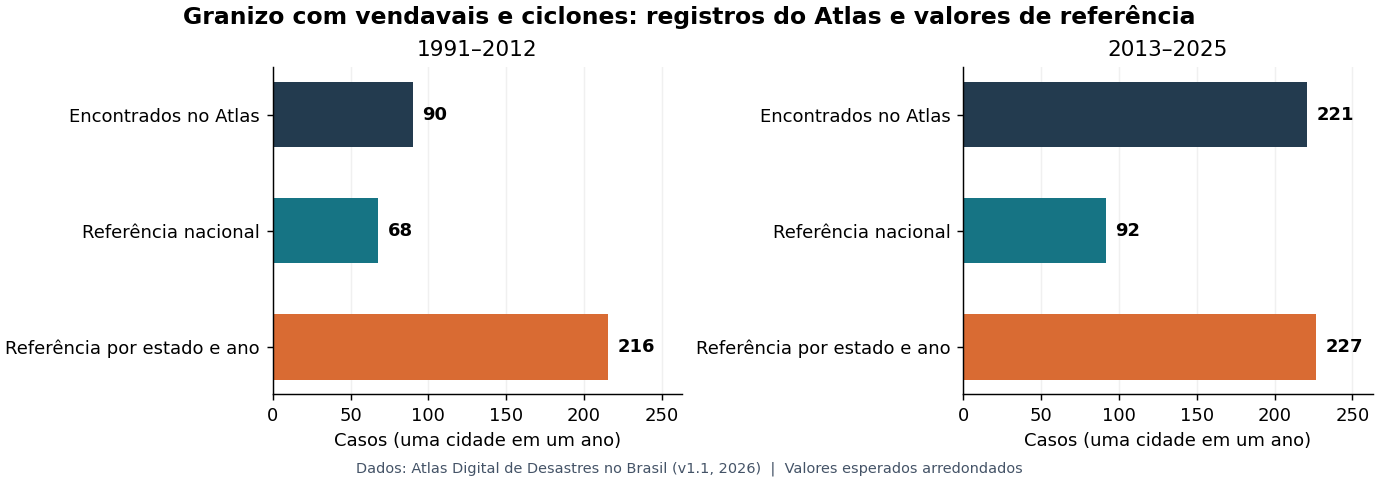


### O resumo em quatro números

**33** combinações apareceram nos dois períodos. **8** tiveram pelo menos 30 casos em cada período e estão na tabela acima. Entre essas mesmas oito, **1** ficou pelo menos 20% acima da referência nacional nos dois períodos (granizo com vendavais e ciclones). Com a referência por estado e ano, **0** chegou a esse limite nos dois períodos.


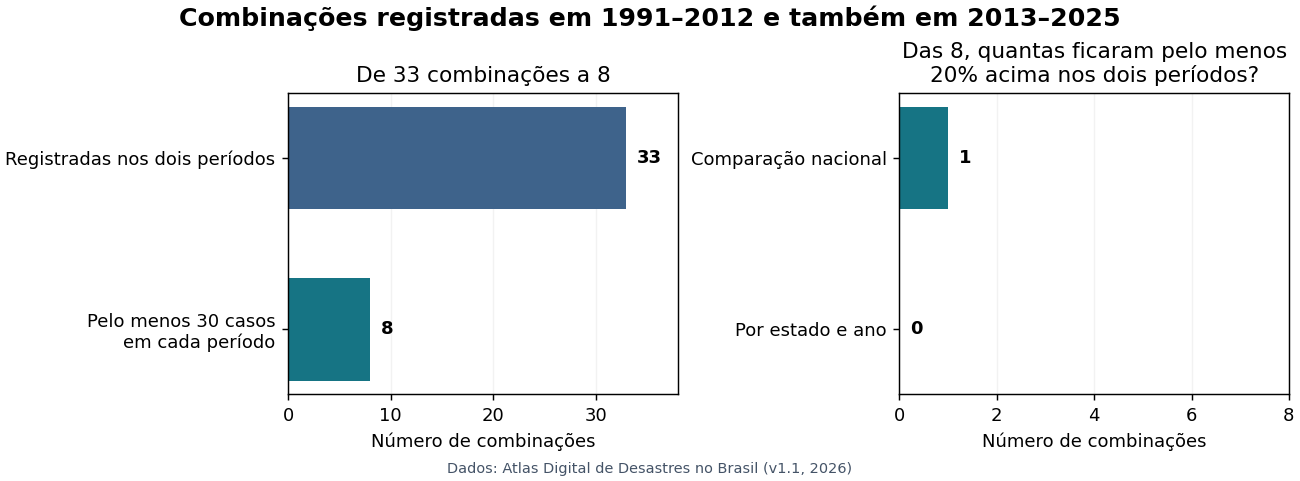

In [1]:
from pathlib import Path
import sys
from IPython.display import Markdown, display

cwd = Path.cwd()
raiz = next((p for p in (cwd, *cwd.parents) if (p / 'codigo/mineradores.py').is_file()), None)
if raiz is None:
    raise FileNotFoundError('Abra o caderno pela pasta do projeto ou por cadernos.')
pasta_codigo = str(raiz / 'codigo')
if pasta_codigo not in sys.path:
    sys.path.insert(0, pasta_codigo)

bytecode_anterior = sys.dont_write_bytecode
try:
    sys.dont_write_bytecode = True
    import preparar_matriz as analise
finally:
    sys.dont_write_bytecode = bytecode_anterior

resumo, qualidade, tempos, pares, regras, robustez, sensibilidade, triagem, duplas, alternativa = analise.executar(raiz)

display(duplas[['Juntos · 1991–2012', 'Juntos · 2013–2025']]
        .rename(columns={'Juntos · 1991–2012': 'Casos em 1991–2012',
                         'Juntos · 2013–2025': 'Casos em 2013–2025'})
        .rename_axis('Tipos de desastre registrados juntos'))

display(Markdown("""
### O que significa «esperado» no gráfico?

É um **número de referência calculado com os dados do Atlas**. Usamos a frequência de cada tipo para estimar quantas vezes eles apareceriam juntos se ocorressem de forma independente. Por exemplo, se em 100 cidades-ano um tipo aparece em 10% e o outro em 20%, a referência é 2 cidades-ano com os dois (10% × 20% × 100).

Em **2013–2025**, encontramos **221** casos no Atlas. Se usamos as frequências do país inteiro, a conta de referência dá cerca de **92**. Se usamos as frequências de cada estado (ou Distrito Federal) em cada ano e somamos os resultados, a referência sobe para **227**, perto dos 221 encontrados.
"""))
analise.grafico_principal(robustez)

display(Markdown("""
### O resumo em quatro números

**33** combinações apareceram nos dois períodos. **8** tiveram pelo menos 30 casos em cada período e estão na tabela acima. Entre essas mesmas oito, **1** ficou pelo menos 20% acima da referência nacional nos dois períodos (granizo com vendavais e ciclones). Com a referência por estado e ano, **0** chegou a esse limite nos dois períodos.
"""))
analise.grafico_triagem(triagem)


### Origem e qualidade dos dados

Importamos no Jupyter a base tratada da Atividade 1, derivada do **Atlas Digital de Desastres no Brasil, v1.1**. Ela tem **76.190 protocolos**. Conferimos os códigos municipais no IBGE, o preenchimento dos campos usados, as datas e as duplicatas. Na tabela, os 180 registros com município, data e tipo iguais têm protocolos distintos. A análise conta uma única presença de cada tipo por cidade e ano.

**Ano do desastre e ano de cadastro.** O período é definido pela data em que o desastre aconteceu. Assim, **88 protocolos cadastrados em 2026** entram em 2025 porque os eventos ocorreram em 2025. Em outros 12 casos, a data de cadastro aparece antes da data do evento. Essa inconsistência está indicada na tabela.

Separamos **1991–2012** e **2013–2025** porque a forma de registrar mudou com a adoção do Sistema Integrado de Informações sobre Desastres (S2ID). O [guia](../documentacao/Analise_e_reproducao.md) mostra onde estão a base original e a tratada e descreve o preparo. Na figura de cobertura, o percentual considera apenas cidades e anos com algum registro no Atlas.


,Protocolos,Município-anos,Com 2+ categorias comparáveis,Pares em destaque
Período,,,,
1991–2012,31590,27528,2368,1
2013–2025,44600,29667,5454,20


,Quantidade
Protocolos distintos,76190
Linhas integralmente duplicadas,0
Campos vazios entre os usados,0
Outras colunas com vazios,6
"Registros com o mesmo município, data e tipo",180
Protocolos cuja data de registro é anterior à do evento,12
Eventos de 2025 registrados em 2026,88
Códigos de municípios conferidos no IBGE,5256


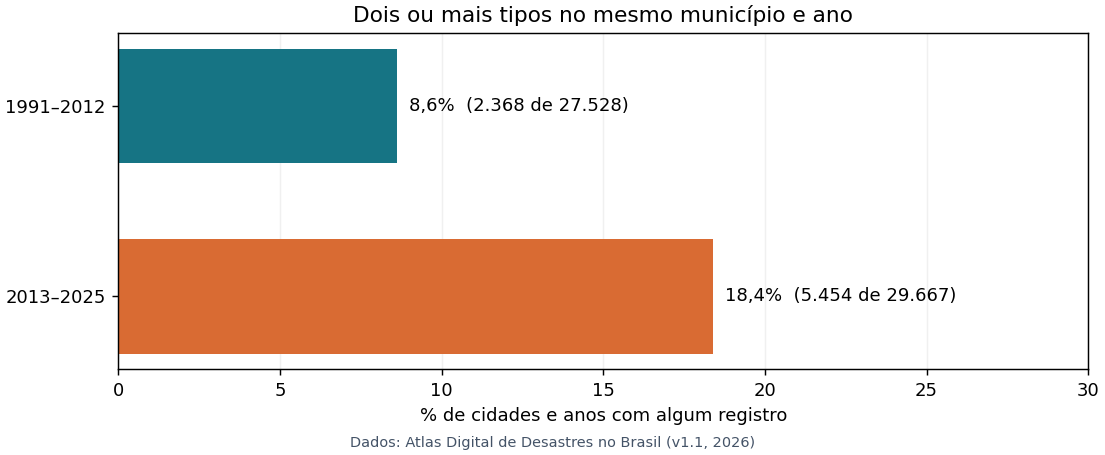

In [2]:
display(resumo.rename_axis('Período'))
rotulos_qualidade = {
    'Linhas em chaves repetidas de município, data e código':
        'Registros com o mesmo município, data e tipo',
    'Protocolos com registro anterior à data do evento':
        'Protocolos cuja data de registro é anterior à do evento',
    'Protocolos recentes registrados em 2026':
        'Eventos de 2025 registrados em 2026',
    'Códigos municipais conferidos com o IBGE':
        'Códigos de municípios conferidos no IBGE',
}
display(analise.pd.Series(qualidade, name='Quantidade').rename(index=rotulos_qualidade).to_frame())
analise.grafico_periodos(resumo)

### Como medimos as combinações

Para cada cidade e ano com algum registro, marcamos os tipos que apareceram. Três registros de granizo no mesmo ano e na mesma cidade contam como uma presença de granizo. Para comparar os períodos, reunimos chuvas intensas, enxurradas, inundações e alagamentos em **Chuva e processos hidrológicos**. Onda de calor e baixa umidade aparece só no período recente e ficou fora da comparação entre tipos. A análise principal usa **12 categorias**.

#### Como ler os números de granizo com vendavais

| Medida | O que significa | Exemplo em 2013–2025 |
| --- | --- | --- |
| **Suporte** | Entre todas as cidades e anos com algum registro, qual porcentagem teve os dois tipos? | **0,74%**. Foram 221 de 29.667. |
| **Confiança** | Entre as cidades e anos com granizo, qual porcentagem também teve vendavais e ciclones? | **19,45%**. Cerca de 19 em cada 100 com granizo. |
| **Lift** | Dividimos a quantidade de casos encontrados pela quantidade esperada. | **2,41**. Houve cerca de 2,4 vezes o esperado pela comparação nacional. |

Para entrar na seleção, a combinação precisava aparecer em pelo menos **30 casos em cada período**. Para ganhar destaque, precisava ainda ficar **20% ou mais acima da referência** nos dois períodos (lift de pelo menos **1,20**).


In [3]:
foco = []
for periodo, tabela in regras.items():
    regra = tabela.loc[tabela.antecedente.eq('Granizo') & tabela.consequente.eq('Vendavais e Ciclones')].iloc[0]
    foco.append({
        'Período': periodo,
        'Casos com os dois tipos': regra.n_AB,
        'Suporte': f'{100 * regra.suporte:.2f}%'.replace('.', ','),
        'Confiança (entre casos com granizo)': f'{100 * regra.confianca:.2f}%'.replace('.', ','),
        'Lift nacional': f'{regra.lift:.2f}'.replace('.', ','),
    })
display(analise.pd.DataFrame(foco).set_index('Período'))

,Casos com os dois tipos,Suporte,Confiança (entre casos com granizo),Lift nacional
Período,,,,
1991–2012,90,"0,33%","8,77%","1,33"
2013–2025,221,"0,74%","19,45%","2,41"


### Por que o resultado muda quando olhamos por estado e ano?

A contagem de **221 casos** de granizo com vendavais e ciclones em 2013–2025 permanece igual. O que muda é quanto esperamos encontrar juntos. Primeiro, usamos a frequência de cada tipo no Brasil inteiro. Depois, repetimos a conta para cada estado ou Distrito Federal e ano, e somamos os valores esperados.

No período recente, dividimos os 221 casos observados pelo número esperado. Com os valores completos, o resultado é **2,41** pela comparação nacional e **0,97** pela comparação por estado e ano. Um resultado de **1** significa que o número encontrado é igual ao esperado. O gráfico arredonda os números esperados para facilitar a leitura. No primeiro período, a razão cai de **1,33** para **0,42**. O Sul concentrou **79 dos 90 casos** no histórico e **187 dos 221** no período recente.

Das **33 combinações** registradas nos dois períodos, **oito** apareceram em pelo menos 30 casos em cada um. Pela comparação nacional, só granizo com vendavais e ciclones passou do limite de 20% acima do esperado nos dois períodos. Na comparação por estado e ano, nenhuma das oito passou desse limite nos dois períodos.

Também repetimos a análise com os **4.413 municípios** presentes nos períodos completos, com os **4.264 municípios** presentes nas duas janelas exatas de 13 anos e sem os registros de 2024. A interpretação se manteve. Quando examinamos os tipos de chuva separadamente, alagamentos e movimento de massa também se destacaram na comparação nacional.


In [4]:
teste_minimo = analise.pd.DataFrame({
    'Mínimo de casos por período': [15, 30, 50],
    'Duplas em destaque nos dois períodos': list(sensibilidade.values()),
    'Dupla em destaque': ['Granizo + vendavais e ciclones'] * 3,
}).set_index('Mínimo de casos por período')
display(teste_minimo)

display(robustez[['Juntos', 'Lift', 'Observado / esperado por UF e ano']]
        .rename(columns={'Juntos': 'Casos com os dois tipos', 'Lift': 'Lift geral',
                         'Observado / esperado por UF e ano': 'Razão por UF e ano'})
        .round(2))
display(alternativa[['Juntos', 'Lift', 'Observado / esperado por UF e ano']].round(2))

,Duplas em destaque nos dois períodos,Dupla em destaque
Mínimo de casos por período,,
15,1,Granizo + vendavais e ciclones
30,1,Granizo + vendavais e ciclones
50,1,Granizo + vendavais e ciclones


,Casos com os dois tipos,Lift geral,Razão por UF e ano
1991–2012,90.0,1.33,0.42
2013–2025,221.0,2.41,0.97
Municípios em ambos · 1991–2012,90.0,1.39,0.43
Municípios em ambos · 2013–2025,221.0,2.47,1.01
Janelas de 13 anos · 2000–2012,73.0,1.32,0.44
Janelas de 13 anos · 2013–2025,221.0,2.47,1.01
"2013–2025, sem 2024",206.0,2.36,0.95
"2013–2025, sem RS em 2024",209.0,2.39,0.94


Juntos  ...  Observado / esperado por UF e ano
Dupla                            Período            ...                                   
Alagamentos + Movimento de Massa 1991–2012      35  ...                               0.81
                                 2013–2025     151  ...                               2.02
Granizo + Vendavais e Ciclones   1991–2012      90  ...                               0.42
                                 2013–2025     221  ...                               0.97

[4 rows x 3 columns]

### Comparação dos algoritmos

Testamos **Apriori, FP-Growth e Eclat** com a mesma base e a mesma regra de seleção. Apriori filtra as combinações possíveis, FP-Growth organiza os registros em uma árvore e Eclat cruza as listas de cidades e anos de cada tipo.

Os três encontraram **as mesmas combinações**: 8 em 1991–2012 e 34 em 2013–2025, considerando o mínimo de 30 casos em cada período separadamente. As 8 da tabela de abertura são as que passaram pelo mínimo **nos dois períodos**. Conferimos as contagens diretamente na base de análise.

Como os resultados foram iguais, comparamos o **tempo de mineração**. Rodamos cada algoritmo sete vezes por período após uma rodada de aquecimento. A **mediana** é o tempo que fica no meio das sete medições. Q1 e Q3 mostram a faixa que contém a metade central dos tempos. Quanto menor a barra, mais rápido foi o algoritmo neste teste.


Mediana (ms)  Q1 (ms)  Q3 (ms)  Repetições  \
Período   Algoritmo                                               
1991–2012 Apriori           56.26    55.80    57.19           7   
          FP-Growth         42.03    41.62    43.48           7   
          Eclat              2.23     2.14     2.27           7   
2013–2025 Apriori           60.64    60.34    60.98           7   
          FP-Growth         46.59    46.16    47.38           7   
          Eclat              3.07     2.94     3.13           7   

                     Duplas com 30+ município-anos  
Período   Algoritmo                              
1991–2012 Apriori                             8  
          FP-Growth                           8  
          Eclat                               8  
2013–2025 Apriori                            34  
          FP-Growth                          34  
          Eclat                              34

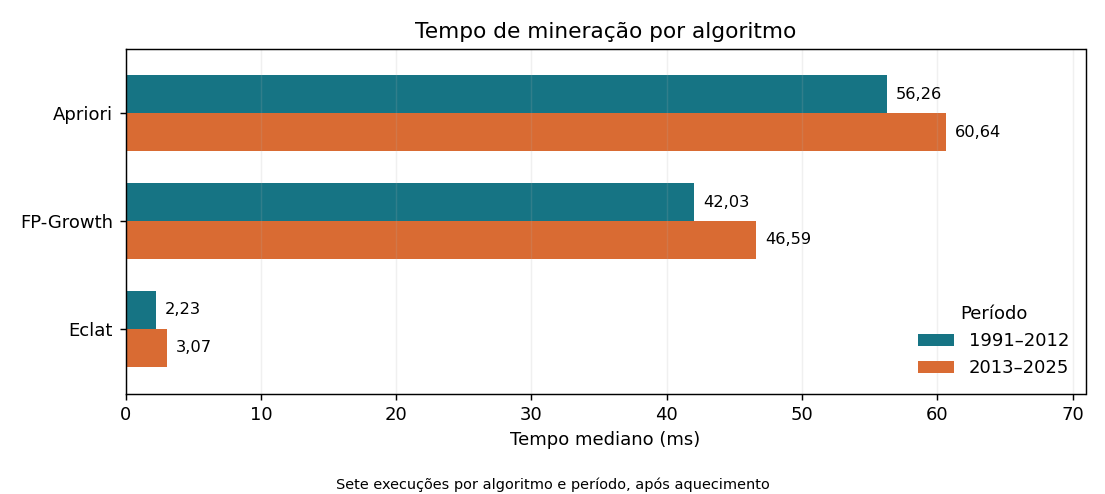

In [5]:
display(tempos.reset_index(level=0).set_index(['Período', 'Algoritmo']).rename(columns={'Pares': 'Duplas com 30+ município-anos'}).round(2))
analise.grafico_algoritmos(tempos)

**Eclat foi a melhor opção neste teste.** Entregou os mesmos resultados e teve a menor mediana de tempo nos dois períodos. A escolha vale para este conjunto com poucas categorias, para pares e para as implementações que usamos. Os tempos podem variar em outra máquina ou em um problema maior.

### Limites da análise

O Atlas reúne registros administrativos. O resultado depende de quais desastres foram registrados, de como foram classificados e de onde e quando os registros se concentram. As medidas descrevem os municípios nos anos em que tiveram algum registro no Atlas. A comparação por UF e ano leva em conta o contexto dos registros, mas ainda pode reunir municípios com exposições diferentes. A análise aponta duplas para investigar. Para saber se os registros vieram do mesmo episódio ou se um tipo de desastre contribuiu para outro, precisaríamos de outras informações.

Mostramos resultados agregados e usamos a versão tratada da Atividade 1, da qual já foram retirados os campos de descrição livre. Usamos os números de protocolo para verificar a qualidade dos dados.

### Avaliação do Jupyter Notebook

Fizemos a mineração em **Python** e usamos o **Jupyter Notebook** para organizar, executar e apresentar a análise. As tabelas geradas com pandas facilitaram a conferência das contagens. Os gráficos do Matplotlib ajudaram a comparar os períodos e os tempos dos três algoritmos. Para a leitura, podemos recolher o código e deixar as saídas visíveis.

O principal cuidado para repetir a análise é escolher o ambiente Python do projeto e executar as células em ordem. As primeiras preparam os dados que as demais usam. Para conferir a reprodução, reiniciamos o kernel do projeto e executamos as cinco células de código. Os três algoritmos voltaram a encontrar 8 pares em 1991–2012 e 34 em 2013–2025. Eclat voltou a ter o menor tempo mediano. O [guia de reprodução](../documentacao/Analise_e_reproducao.md) traz os passos para repetir o teste.

### Referências

- Material da disciplina *Mineração de Dados*, seção de regras de associação.
- [Manual de Aplicação do Atlas Digital](https://atlasdigital.mdr.gov.br/arquivos/Atlas_Digital_Desastres_Manual_Aplicacao.pdf), pp. 17–19, e [SINISA 2025, Águas Pluviais](https://www.gov.br/cidades/pt-br/acesso-a-informacao/acoes-e-programas/saneamento/sinisa/resultados-sinisa/RELATORIO_SINISA_AGUAS_PLUVIAIS_2025.pdf), pp. 42–44.
- [IBGE, Divisão Territorial Brasileira 2013](https://geoftp.ibge.gov.br/organizacao_do_territorio/estrutura_territorial/divisao_territorial/2013/) e [2025](https://geoftp.ibge.gov.br/organizacao_do_territorio/estrutura_territorial/divisao_territorial/2025/).
- [Agrawal e Srikant (1994), Apriori](https://www.vldb.org/conf/1994/P487.PDF), [Han et al. (2004), FP-Growth](https://doi.org/10.1023/B:DAMI.0000005258.31418.83) e [Zaki (2000), Eclat](https://www.cs.rpi.edu/~zaki/publications/).